# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: __________________________    Group: __________    Date: __________

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [ ]:
np.random.seed(42)

years = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)

salary = intercept + slope * years + noise

df = pd.DataFrame({"YearsOfExperience": years, "Salary": salary})

display(df.head())
print("Shape:", df.shape)   # (500, 2)

,YearsOfExperience,Salary
0,8,115037.780010
1,16,182309.972927
2,12,156442.408989
3,9,144753.562169
4,8,130798.818454


Shape: (500, 2)


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [ ]:
print("Shape:", df.shape)
display(df.describe())
print("Missing values:\n", df.isna().sum())
print("Correlation:", df["YearsOfExperience"].corr(df["Salary"]))

Shape: (500, 2)


,YearsOfExperience,Salary
count,500.000000,500.000000
mean,10.616000,142570.011096
std,5.662922,44935.263058
min,2.000000,54881.134555
25%,5.750000,104426.300731
50%,10.000000,139865.032545
75%,16.000000,182341.125962
max,20.000000,241879.376204


Missing values:
 YearsOfExperience    0
Salary               0
dtype: int64
Correlation: 0.975058457607618


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

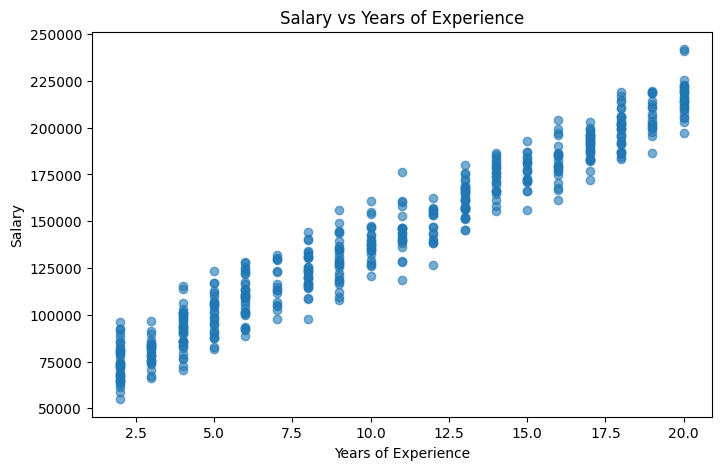

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.6)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")
plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [ ]:
X = df[["YearsOfExperience"]]   # DataFrame ثنائي الأبعاد (دبل أقواس)
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))   # 400
print("Test records:", len(X_test))        # 100

Training records: 400
Test records: 100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)

print("Slope:", lr.coef_[0])
print("Intercept:", lr.intercept_)
print("Train R2:", lr.score(X_train, y_train))
print("Test R2:", lr.score(X_test, y_test))

Slope: 7696.612923052044
Intercept: 60961.340880280564
Train R2: 0.9488372177019488
Test R2: 0.9573704756930141


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [ ]:
y_pred = lr.predict(X_test)

lr_mae = mean_absolute_error(y_test, y_pred)
lr_mse = mean_squared_error(y_test, y_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_pred)

print(f"MAE : {lr_mae:.2f}")
print(f"MSE : {lr_mse:.2f}")
print(f"RMSE: {lr_rmse:.2f}")
print(f"R2  : {lr_r2:.4f}")

comparison = pd.DataFrame({
    "Actual": y_test.values[:5],
    "Predicted": y_pred[:5]
})
display(comparison)

MAE : 7905.11
MSE : 93933277.38
RMSE: 9691.92
R2  : 0.9574


,Actual,Predicted
0,123631.230350,107141.018419
1,139775.630647,122534.244265
2,93184.812446,107141.018419
3,166740.803478,161017.308880
4,174587.183981,184107.147649


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [ ]:
baseline_pred = np.full(len(y_test), y_train.mean())

base_mae = mean_absolute_error(y_test, baseline_pred)
base_mse = mean_squared_error(y_test, baseline_pred)
base_rmse = np.sqrt(base_mse)
base_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline MAE : {base_mae:.2f}  | Linear Regression MAE : {lr_mae:.2f}")
print(f"Baseline RMSE: {base_rmse:.2f} | Linear Regression RMSE: {lr_rmse:.2f}")

Baseline MAE : 40444.96  | Linear Regression MAE : 7905.11
Baseline RMSE: 46953.77 | Linear Regression RMSE: 9691.92


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

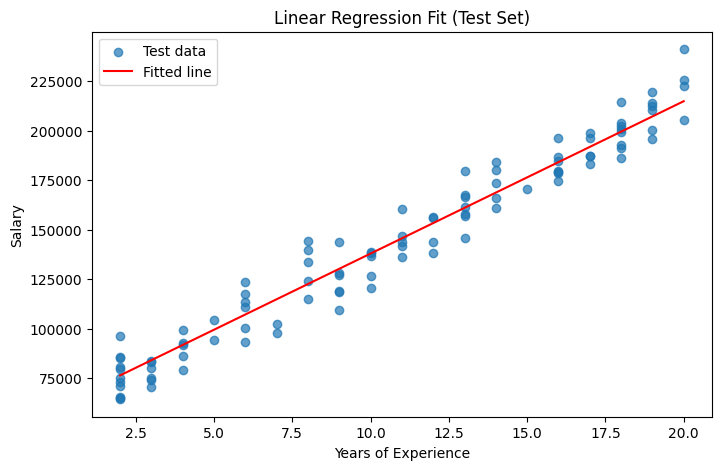

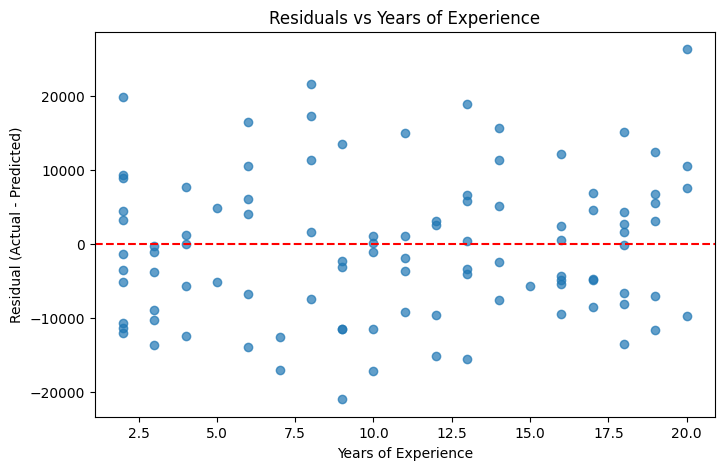

In [ ]:
# (a) Test observations + fitted line
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.7, label="Test data")
x_line = pd.DataFrame({"YearsOfExperience": np.linspace(2, 20, 100)})
plt.plot(x_line, lr.predict(x_line), color="red", label="Fitted line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression Fit (Test Set)")
plt.legend()
plt.show()

# (b) Residuals
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Years of Experience")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Years of Experience")
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [ ]:
new_X = pd.DataFrame({"YearsOfExperience": [5, 10, 15]})
new_pred = lr.predict(new_X)

results = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15],
    "PredictedSalary": new_pred
})
display(results)

,YearsOfExperience,PredictedSalary
0,5,99444.405496
1,10,137927.470111
2,15,176410.534726


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [ ]:
ridge_models = {}
for a in [10, 100]:
    m = Ridge(alpha=a)
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_test_scaled)
    ridge_models[a] = m
    print(f"Ridge alpha={a}: coef={m.coef_[0]:.2f}, "
          f"MAE={mean_absolute_error(y_test, p):.2f}, "
          f"R2={r2_score(y_test, p):.4f}")

ridge10 = ridge_models[10]   # نحتفظ به للمهمة 13

Ridge alpha=10: coef=42156.50, MAE=8084.46, R2=0.9557
Ridge alpha=100: coef=34568.33, MAE=11308.37, R2=0.9118


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [ ]:
lasso_models = {}
for a in [1000, 10000, 50000]:
    m = Lasso(alpha=a, max_iter=20000)
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_test_scaled)
    lasso_models[a] = m
    print(f"Lasso alpha={a}: coef={m.coef_[0]:.2f}, "
          f"MAE={mean_absolute_error(y_test, p):.2f}, "
          f"R2={r2_score(y_test, p):.4f}")

lasso1000 = lasso_models[1000]   # نحتفظ به للمهمة 13

Lasso alpha=1000: coef=42210.42, MAE=8074.65, R2=0.9558
Lasso alpha=10000: coef=33210.42, MAE=12287.96, R2=0.8980
Lasso alpha=50000: coef=0.00, MAE=40444.96, R2=-0.0005


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [ ]:
def metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return [mean_absolute_error(y_true, y_hat), np.sqrt(mse), r2_score(y_true, y_hat)]

summary = pd.DataFrame(
    {
        "Mean Baseline": metrics(y_test, baseline_pred),
        "Linear Regression": metrics(y_test, lr.predict(X_test)),
        "Ridge (alpha=10)": metrics(y_test, ridge10.predict(X_test_scaled)),
        "Lasso (alpha=1000)": metrics(y_test, lasso1000.predict(X_test_scaled)),
    },
    index=["Test MAE", "Test RMSE", "Test R2"]
).T

display(summary)

,Test MAE,Test RMSE,Test R2
Mean Baseline,40444.957874,46953.769510,-0.000534
Linear Regression,7905.114729,9691.918148,0.957370
Ridge (alpha=10),8084.461348,9876.931577,0.955727
Lasso (alpha=1000),8074.651463,9864.608230,0.955838


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.